# Linguistic Bias — Modeling

## 1. Data Preparation


In [2]:
from datasets import load_dataset
import pandas as pd
import numpy as np

RANDOM_STATE = 42

# Load Linguistic Bias dataset
ds = load_dataset("mediabiasgroup/mbib-base")
df = ds["linguistic_bias"].to_pandas()

# Create a copy for cleaning
clean_df = df.copy()

# Normalize text for duplicate detection
clean_df["normalized_text"] = (
    clean_df["text"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify conflicting labels
label_counts = (
    clean_df.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_keys = label_counts[
    label_counts > 1
].index

# Remove conflicting text groups
clean_df = clean_df[
    ~clean_df["normalized_text"].isin(conflicting_keys)
].copy()

# Remove consistent normalized duplicates
clean_df = clean_df.drop_duplicates(
    subset=["normalized_text"],
    keep="first"
).copy()

# Validate dataset
assert clean_df["label"].isin([0, 1]).all()
assert clean_df["normalized_text"].is_unique
assert clean_df["text"].notna().all()

print("Original dataset:", df.shape)
print("Cleaned dataset:", clean_df.shape)

display(clean_df["label"].value_counts())

Original dataset: (401862, 4)
Cleaned dataset: (400657, 5)


label
0    200426
1    200231
Name: count, dtype: int64

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

# Group samples sharing the same ID in Source 75.
# Other sources use a unique group per row.
groups = pd.Series(
    np.where(
        clean_df["dataset_id"] == 75,
        clean_df["dataset_id"].astype(str) + "_" + clean_df["id"].astype(str),
        "row_" + clean_df.index.astype(str)
    ),
    index=clean_df.index
)

# First split: approximately 80% train / 20% temporary
cv_outer = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    cv_outer.split(
        clean_df["text"],
        clean_df["label"],
        groups
    )
)

train_df = clean_df.iloc[train_idx].copy()
temp_df = clean_df.iloc[temp_idx].copy()

# Second split: temporary data into validation and test
temp_groups = groups.iloc[temp_idx]

cv_inner = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    cv_inner.split(
        temp_df["text"],
        temp_df["label"],
        temp_groups
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Check results
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        len(subset),
        f"({len(subset)/len(clean_df)*100:.2f}%)",
        subset["label"].value_counts(normalize=True).round(3).to_dict()
    )

Train 320422 (79.97%) {0: 0.5, 1: 0.5}
Validation 40144 (10.02%) {1: 0.5, 0: 0.5}
Test 40091 (10.01%) {0: 0.501, 1: 0.499}


In [4]:
# Data Leakage Check
# Check text overlap across splits

def check_overlap(col):
    train = set(train_df[col])
    val = set(val_df[col])
    test = set(test_df[col])

    print(f"\n{col} overlap:")
    print("Train / Validation:", len(train & val))
    print("Train / Test:", len(train & test))
    print("Validation / Test:", len(val & test))


check_overlap("normalized_text")

# Check related IDs in Source 75
train_ids = set(train_df.loc[train_df["dataset_id"] == 75, "id"])
val_ids = set(val_df.loc[val_df["dataset_id"] == 75, "id"])
test_ids = set(test_df.loc[test_df["dataset_id"] == 75, "id"])

print("\nSource 75 ID overlap:")
print("Train / Validation:", len(train_ids & val_ids))
print("Train / Test:", len(train_ids & test_ids))
print("Validation / Test:", len(val_ids & test_ids))

# Verify all records are accounted for
assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)


normalized_text overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Source 75 ID overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [5]:
# Representative Training Sample
# Allocate samples across sources and labels
source_label_counts = (
    train_df.groupby(["dataset_id", "label"])
    .size()
)

# Reserve a minimum for smaller groups where feasible
min_per_group = 200

base = source_label_counts.clip(upper=min_per_group)
remaining = 40000 - base.sum()

available = source_label_counts - base

extra = (
    remaining * available / available.sum()
).astype(int)

allocation = (base + extra).astype(int)

# Assign any remaining samples
leftover = 40000 - allocation.sum()

for group in available.sort_values(ascending=False).index:
    if leftover == 0:
        break
    if allocation[group] < source_label_counts[group]:
        allocation[group] += 1
        leftover -= 1

# Sample each source-label group
train_sample = pd.concat([
    group.sample(
        n=int(allocation.loc[key]),
        random_state=42
    )
    for key, group in train_df.groupby(["dataset_id", "label"])
])

train_sample = train_sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Training subset size:", len(train_sample))

display(
    pd.crosstab(
        train_sample["dataset_id"],
        train_sample["label"]
    )
)

Training subset size: 40000


label,0,1
dataset_id,,
3,1090,315
9,0,310
10,351,329
26,17014,15316
35,723,2904
38,31,241
75,638,738


In [5]:
# Data Preparation
# Compare the training sample with the full training set
comparison = pd.DataFrame({
    "Full Train (%)": train_df["label"].value_counts(normalize=True) * 100,
    "Sample (%)": train_sample["label"].value_counts(normalize=True) * 100
}).round(2)

display(comparison)

# Verify the sample contains only training records
assert set(train_sample["normalized_text"]).issubset(
    set(train_df["normalized_text"])
)

# Check sample source distribution
display(
    (train_sample["dataset_id"].value_counts(normalize=True) * 100)
    .round(2)
)

,Full Train (%),Sample (%)
label,,
0,50.02,49.62
1,49.98,50.38


dataset_id
26    80.82
35     9.07
3      3.51
75     3.44
10     1.70
9      0.78
38     0.68
Name: proportion, dtype: float64

## 2. Baseline Models

### 2.1 Dummy Classifier

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_train = train_sample["text"]
y_train = train_sample["label"]

X_val = val_df["text"]
y_val = val_df["label"]

dummy = DummyClassifier(
    strategy="prior",
    random_state=42
)

# DummyClassifier only needs sample counts and labels
dummy.fit(X_train, y_train)

dummy_prob = dummy.predict_proba(X_val)[:, 1]
dummy_pred = dummy.predict(X_val)

dummy_results = {
    "Model": "Dummy Classifier",
    "ROC-AUC": roc_auc_score(y_val, dummy_prob),
    "PR-AUC": average_precision_score(y_val, dummy_prob),
    "Accuracy": accuracy_score(y_val, dummy_pred),
    "Precision": precision_score(y_val, dummy_pred, zero_division=0),
    "Recall": recall_score(y_val, dummy_pred, zero_division=0),
    "F1": f1_score(y_val, dummy_pred, zero_division=0)
}

display(pd.DataFrame([dummy_results]).round(4))

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5,0.5002,0.5002,0.5002,1.0,0.6668


### 2.2 TF-IDF + Logistic Regression

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5000,0.5002,0.5002,0.5002,1.0000,0.6668
1,TF-IDF + Logistic Regression,0.6501,0.6676,0.6042,0.6158,0.5547,0.5836


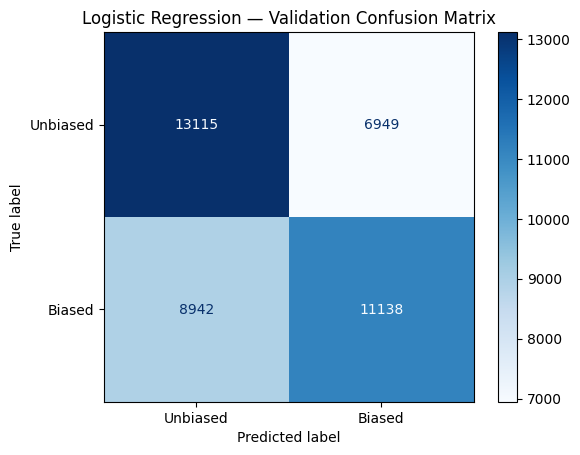

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

lr_prob = lr_pipeline.predict_proba(X_val)[:, 1]
lr_pred = lr_pipeline.predict(X_val)

lr_results = {
    "Model": "TF-IDF + Logistic Regression",
    "ROC-AUC": roc_auc_score(y_val, lr_prob),
    "PR-AUC": average_precision_score(y_val, lr_prob),
    "Accuracy": accuracy_score(y_val, lr_pred),
    "Precision": precision_score(y_val, lr_pred, zero_division=0),
    "Recall": recall_score(y_val, lr_pred, zero_division=0),
    "F1": f1_score(y_val, lr_pred, zero_division=0)
}

display(pd.DataFrame([dummy_results, lr_results]).round(4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    lr_pred,
    display_labels=["Unbiased", "Biased"],
    cmap="Blues"
)
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.show()

In [9]:
# 3-Fold Cross-Validation
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Groups for the 40k training sample
cv_groups = np.where(
    train_sample["dataset_id"].eq(75),
    "source75_" + train_sample["id"].astype(str),
    "row_" + train_sample.index.astype(str)
)

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    groups=cv_groups,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
        "f1": "f1"
    },
    n_jobs=1
)

display(
    pd.DataFrame({
        "ROC-AUC": cv_results["test_roc_auc"],
        "PR-AUC": cv_results["test_average_precision"],
        "F1": cv_results["test_f1"]
    }, index=["Fold 1", "Fold 2", "Fold 3"]).round(4)
)

print(
    "Mean CV ROC-AUC:",
    round(cv_results["test_roc_auc"].mean(), 4)
)

,ROC-AUC,PR-AUC,F1
Fold 1,0.6379,0.6602,0.5836
Fold 2,0.6505,0.6666,0.5893
Fold 3,0.6385,0.6537,0.5830


Mean CV ROC-AUC: 0.6423


### Baseline — Key Findings

- Logistic Regression achieved a validation ROC-AUC of **0.6501**, outperforming the Dummy baseline (0.5000).
- The mean 3-Fold Cross-Validation ROC-AUC was **0.6423**.
- Performance was relatively consistent across folds (0.6379–0.6505).
- The model showed limited recall for biased texts (0.5547).

**Conclusion:** The baseline demonstrates predictive ability above chance, but further improvement is needed.

### 2.3 Logistic Regression — Full Training Set

In [10]:
from sklearn.base import clone

# Same pipeline and hyperparameters as the baseline
lr_full = clone(lr_pipeline)

X_train_full = train_df["text"]
y_train_full = train_df["label"]

# Train using the complete training set
lr_full.fit(X_train_full, y_train_full)

# Evaluate on the same validation set
lr_full_prob = lr_full.predict_proba(X_val)[:, 1]
lr_full_pred = lr_full.predict(X_val)

lr_full_results = {
    "Model": "Logistic Regression — Full Train",
    "ROC-AUC": roc_auc_score(y_val, lr_full_prob),
    "PR-AUC": average_precision_score(y_val, lr_full_prob),
    "Accuracy": accuracy_score(y_val, lr_full_pred),
    "Precision": precision_score(y_val, lr_full_pred, zero_division=0),
    "Recall": recall_score(y_val, lr_full_pred, zero_division=0),
    "F1": f1_score(y_val, lr_full_pred, zero_division=0)
}

display(pd.DataFrame([dummy_results, lr_results, lr_full_results]).round(4))

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5000,0.5002,0.5002,0.5002,1.0000,0.6668
1,TF-IDF + Logistic Regression,0.6501,0.6676,0.6042,0.6158,0.5547,0.5836
2,Logistic Regression — Full Train,0.6838,0.7048,0.6321,0.6614,0.5419,0.5957


### Key Findings — Full Training Experiment

- Training Logistic Regression on the full dataset improved ROC-AUC from **0.6501 to 0.6838**.
- PR-AUC increased from **0.6676 to 0.7048**, with a slight improvement in F1.
- The full-data Logistic Regression outperformed both the 40K baseline and LSTM on the primary evaluation metric.
- Recall remains a limitation despite the overall improvement.

**Conclusion:** Increasing the training data improved model performance. Full-data Logistic Regression is currently the strongest candidate for final evaluation.

## 3. LSTM Model
### 3.1 Tokenization & Padding

In [11]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

tf.keras.utils.set_random_seed(42)

MAX_TOKENS = 20000

# Determine sequence length using training texts only
train_lengths = X_train.str.split().str.len()
MAX_LENGTH = int(train_lengths.quantile(0.95))

print("Vocabulary limit:", MAX_TOKENS)
print("Sequence length:", MAX_LENGTH)

vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary from training data only
vectorizer.adapt(X_train.to_numpy())

print("Actual vocabulary size:", len(vectorizer.get_vocabulary()))

Vocabulary limit: 20000
Sequence length: 257
Actual vocabulary size: 20000


In [12]:
# Check Tokenization & Padding
sample_texts = X_train.iloc[:3]

tokenized = vectorizer(
    tf.constant(sample_texts.tolist())
)

print("Tokenized shape:", tokenized.shape)
print("First 20 token IDs:", tokenized[0][:20].numpy())
print("Padding token ID:", 0)
print("Sequence length:", tokenized.shape[1])

Tokenized shape: (3, 257)
First 20 token IDs: [    2  8029   179    12     1    16 10678     4 10678     1     9   153
     1    19     1 10678     4    11    71    17]
Padding token ID: 0
Sequence length: 257


### 3.2 Build & Train LSTM

In [13]:
# Model Architecture

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    Input(shape=(MAX_LENGTH,), dtype="int32"),

    Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 257, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Train LSTM

# Convert texts to integer sequences
X_train_seq = vectorizer(
    tf.constant(X_train.tolist())
)

X_val_seq = vectorizer(
    tf.constant(X_val.tolist())
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_seq,
    y_train.to_numpy(),
    validation_data=(
        X_val_seq,
        y_val.to_numpy()
    ),
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.5652 - loss: 0.6740 - val_accuracy: 0.5955 - val_loss: 0.6618
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.6778 - loss: 0.6038 - val_accuracy: 0.5954 - val_loss: 0.6908
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 65ms/step - accuracy: 0.7775 - loss: 0.4788 - val_accuracy: 0.5695 - val_loss: 0.8220


### 3.3 LSTM Validation Evaluation

In [15]:
# Predict probabilities
lstm_prob = lstm_model.predict(
    X_val_seq,
    batch_size=64,
    verbose=1
).ravel()

# Convert probabilities to labels
lstm_pred = (lstm_prob >= 0.5).astype(int)

lstm_results = {
    "Model": "LSTM",
    "ROC-AUC": roc_auc_score(y_val, lstm_prob),
    "PR-AUC": average_precision_score(y_val, lstm_prob),
    "Accuracy": accuracy_score(y_val, lstm_pred),
    "Precision": precision_score(
        y_val, lstm_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, lstm_pred, zero_division=0
    ),
    "F1": f1_score(
        y_val, lstm_pred, zero_division=0
    )
}

display(
    pd.DataFrame([
        dummy_results,
        lr_results,
        lstm_results
    ]).round(4)
)

628/628 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5000,0.5002,0.5002,0.5002,1.0000,0.6668
1,TF-IDF + Logistic Regression,0.6501,0.6676,0.6042,0.6158,0.5547,0.5836
2,LSTM,0.6283,0.6457,0.5955,0.6668,0.3824,0.4861


### Key Findings — Baseline vs. LSTM

- **Logistic Regression** outperformed LSTM in ROC-AUC (**0.6501 vs. 0.6283**) and PR-AUC (**0.6676 vs. 0.6457**).
- **LSTM** achieved higher Precision (0.6668) but lower Recall (0.3824), missing more biased examples.
- LSTM showed signs of **overfitting**, with increasing validation loss despite improving training accuracy.
- Both models outperformed the Dummy baseline in ROC-AUC.

**Conclusion:** Logistic Regression is currently the stronger baseline. Next, we will train it on the full training set to investigate whether more data improves performance.

### 3.4 LSTM Improvement — Spatial Dropout

In [16]:
from tensorflow.keras.layers import SpatialDropout1D

tf.keras.utils.set_random_seed(42)

lstm_v2 = Sequential([
    Input(shape=(MAX_LENGTH,), dtype="int32"),

    Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    SpatialDropout1D(0.2),

    LSTM(64),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

lstm_v2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_v2 = lstm_v2.fit(
    X_train_seq,
    y_train.to_numpy(),
    validation_data=(X_val_seq, y_val.to_numpy()),
    epochs=10,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.5659 - loss: 0.6740 - val_accuracy: 0.5876 - val_loss: 0.6660
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.6818 - loss: 0.6013 - val_accuracy: 0.6031 - val_loss: 0.6772
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 64ms/step - accuracy: 0.7605 - loss: 0.5023 - val_accuracy: 0.5735 - val_loss: 0.7714


In [17]:
lstm_v2_prob = lstm_v2.predict(
    X_val_seq,
    batch_size=64,
    verbose=0
).ravel()

print(
    "Original LSTM ROC-AUC:",
    round(lstm_results["ROC-AUC"], 4)
)

print(
    "Improved LSTM ROC-AUC:",
    round(roc_auc_score(y_val, lstm_v2_prob), 4)
)

Original LSTM ROC-AUC: 0.6283
Improved LSTM ROC-AUC: 0.6264


### 3.5 LSTM Improvement — Reduce Model Capacity

In [18]:
tf.keras.utils.set_random_seed(42)

lstm_v3 = Sequential([
    Input(shape=(MAX_LENGTH,), dtype="int32"),

    Embedding(
        input_dim=len(vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    LSTM(32),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

lstm_v3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_v3 = lstm_v3.fit(
    X_train_seq,
    y_train.to_numpy(),
    validation_data=(X_val_seq, y_val.to_numpy()),
    epochs=10,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.5428 - loss: 0.6846 - val_accuracy: 0.5625 - val_loss: 0.6810
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.6577 - loss: 0.6185 - val_accuracy: 0.5860 - val_loss: 0.6811
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.7561 - loss: 0.5068 - val_accuracy: 0.5680 - val_loss: 0.7630


In [19]:
lstm_v3_prob = lstm_v3.predict(
    X_val_seq,
    batch_size=64,
    verbose=0
).ravel()

comparison = pd.DataFrame({
    "Model": [
        "Original LSTM",
        "LSTM v2 — Spatial Dropout",
        "LSTM v3 — 32 Units",
        "Logistic Regression — Full Train"
    ],
    "ROC-AUC": [
        lstm_results["ROC-AUC"],
        roc_auc_score(y_val, lstm_v2_prob),
        roc_auc_score(y_val, lstm_v3_prob),
        lr_full_results["ROC-AUC"]
    ]
})

display(comparison.round(4))

,Model,ROC-AUC
0,Original LSTM,0.6283
1,LSTM v2 — Spatial Dropout,0.6264
2,LSTM v3 — 32 Units,0.5851
3,Logistic Regression — Full Train,0.6838


### Key Findings — LSTM Improvement Experiments

- The original LSTM achieved the highest ROC-AUC among the LSTM variants (**0.6283**).
- Adding Spatial Dropout slightly reduced ROC-AUC to **0.6264**.
- Reducing LSTM units from 64 to 32 further decreased ROC-AUC to **0.5851**.
- All LSTM variants showed signs of overfitting during training.
- Full-data Logistic Regression remains the strongest model with a validation ROC-AUC of **0.6838**.

**Conclusion:** Neither LSTM modification improved generalization. Logistic Regression is currently the preferred model based on validation performance.

## 4. Model Comparison & Integration

### 4.1 Error Analysis

In [20]:
# Analyze errors using the best model (Full Train Logistic Regression)

error_df = val_df[
    ["text", "label", "dataset_id"]
].copy()

error_df["predicted_label"] = lr_full_pred
error_df["bias_probability"] = lr_full_prob

# Identify error types
error_df["error_type"] = np.select(
    [
        (error_df["label"] == 0) &
        (error_df["predicted_label"] == 1),

        (error_df["label"] == 1) &
        (error_df["predicted_label"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

# Overall error distribution
display(
    error_df["error_type"]
    .value_counts()
    .to_frame("Count")
)

# Error distribution by source
source_errors = pd.crosstab(
    error_df["dataset_id"],
    error_df["error_type"]
)

display(source_errors)

,Count
error_type,
Correct,25375
False Negative,9199
False Positive,5570


error_type,Correct,False Negative,False Positive
dataset_id,,,
3,886,94,178
9,108,59,0
10,194,56,89
26,20561,8763,4482
35,2851,10,611
38,38,32,3
75,737,185,207


In [21]:
# Error rates within each source
source_error_rates = pd.crosstab(
    error_df["dataset_id"],
    error_df["error_type"],
    normalize="index"
) * 100

display(source_error_rates.round(2))

error_type,Correct,False Negative,False Positive
dataset_id,,,
3,76.51,8.12,15.37
9,64.67,35.33,0.00
10,57.23,16.52,26.25
26,60.82,25.92,13.26
35,82.11,0.29,17.60
38,52.05,43.84,4.11
75,65.28,16.39,18.33


### Key Findings — Error Analysis

- Model performance varies considerably across source datasets.
- Source 35 achieved the highest accuracy (82.11%), while Source 38 had the lowest (52.05%).
- False negatives outnumber false positives overall (9,199 vs. 5,570).
- Source 26 contributes the largest number of errors due to its dominant dataset size.
- Source-specific label distributions may influence model performance.

**Conclusion:** The model's reliability varies across sources, highlighting potential source-related generalization limitations.

### 4.2 Model Comparison

In [22]:
# Compare all models on the same validation set

model_comparison = pd.DataFrame([
    dummy_results,
    lr_results,
    lstm_results,
    lr_full_results
])

display(
    model_comparison.sort_values(
        "ROC-AUC", ascending=False
    ).round(4)
)

best_model_name = model_comparison.loc[
    model_comparison["ROC-AUC"].idxmax(), "Model"
]

print("Best model based on Validation ROC-AUC:", best_model_name)

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
3,Logistic Regression — Full Train,0.6838,0.7048,0.6321,0.6614,0.5419,0.5957
1,TF-IDF + Logistic Regression,0.6501,0.6676,0.6042,0.6158,0.5547,0.5836
2,LSTM,0.6283,0.6457,0.5955,0.6668,0.3824,0.4861
0,Dummy Classifier,0.5000,0.5002,0.5002,0.5002,1.0000,0.6668


Best model based on Validation ROC-AUC: Logistic Regression — Full Train


### Key Findings — Model Comparison

- Full-data Logistic Regression achieved the highest validation ROC-AUC (**0.6838**) and PR-AUC (**0.7048**).
- Increasing the training data improved Logistic Regression performance.
- The original LSTM and its two modified versions did not outperform Logistic Regression.
- Source-dependent performance and false negatives remain important limitations.

**Decision:** Select the full-data Logistic Regression as the current best model, pending final test evaluation.

### 4.3 Save Model Pipeline

In [23]:
import joblib
from pathlib import Path

# Locate the project root
project_root = Path.cwd()

if project_root.name == "modeling":
    project_root = project_root.parent.parent
elif project_root.name == "notebooks":
    project_root = project_root.parent

models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "linguistic_bias_lr.joblib"

# Save the complete pipeline
joblib.dump(lr_full, model_path)

print("Model saved to:", model_path)

Model saved to: /Users/sarahaltaleb/Documents/GitHub/BiasLens/models/linguistic_bias_lr.joblib


### 4.4 Model Loading & Prediction

In [24]:
# Load saved pipeline
loaded_model = joblib.load(model_path)

def predict_bias(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please provide a non-empty text.")

    probability = float(
        loaded_model.predict_proba([text])[0, 1]
    )

    label = int(probability >= 0.5)

    return {
        "bias_type": "linguistic",
        "predicted_label": label,
        "prediction": "Biased" if label == 1 else "Unbiased",
        "bias_probability": round(probability, 4)
    }

In [25]:
sample_text = "The government announced a new education policy."

result = predict_bias(sample_text)

display(pd.DataFrame([result]))

,bias_type,predicted_label,prediction,bias_probability
0,linguistic,0,Unbiased,0.3205


In [26]:
import numpy as np

test_inputs = X_val.iloc[:5].tolist()

original_probs = lr_full.predict_proba(test_inputs)
loaded_probs = loaded_model.predict_proba(test_inputs)

np.testing.assert_allclose(
    original_probs,
    loaded_probs
)

print("Model loading test passed.")

Model loading test passed.


In [27]:
# Cross-Validation Leakage Check

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, cv_groups), start=1
):
    train_groups = set(cv_groups[train_idx])
    val_groups = set(cv_groups[val_idx])

    overlap = train_groups & val_groups

    print(f"Fold {fold}: {len(overlap)} overlapping groups")

    assert len(overlap) == 0

Fold 1: 0 overlapping groups
Fold 2: 0 overlapping groups
Fold 3: 0 overlapping groups


## 5. Additional Experiment — Linear SVM

**Objective:** Evaluate whether Linear SVM improves linguistic bias detection compared to Logistic Regression.

**Hypothesis:** Linear SVM may achieve better generalization by maximizing the separating margin between biased and unbiased examples.

**Evaluation:** Use the same full training set, TF-IDF settings, and validation set. Compare models using ROC-AUC.

In [28]:
from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score

# Reuse the same TF-IDF configuration as Logistic Regression
svm_pipeline = clone(lr_pipeline)

svm_pipeline.set_params(
    classifier=LinearSVC(
        random_state=42,
        max_iter=3000
    )
)

# Train on the same full training dataset
svm_pipeline.fit(X_train_full, y_train_full)

# Evaluate on validation data only
svm_scores = svm_pipeline.decision_function(X_val)
svm_auc = roc_auc_score(y_val, svm_scores)

print(f"Logistic Regression ROC-AUC: {lr_full_results['ROC-AUC']:.4f}")
print(f"Linear SVM ROC-AUC:          {svm_auc:.4f}")
print(f"Difference:                  {svm_auc - lr_full_results['ROC-AUC']:+.4f}")

Logistic Regression ROC-AUC: 0.6838
Linear SVM ROC-AUC:          0.6693
Difference:                  -0.0144


In [29]:
print("SVM Training Samples:", len(X_train_full))
print("Validation Samples:", len(X_val))

print("\nSVM Classifier:")
print(svm_pipeline.named_steps["classifier"])

print("\nTF-IDF Settings:")
print(svm_pipeline.named_steps["tfidf"])

SVM Training Samples: 320422
Validation Samples: 40144

SVM Classifier:
LinearSVC(max_iter=3000, random_state=42)

TF-IDF Settings:
TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 2),
                sublinear_tf=True)


In [30]:
from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.metrics import roc_auc_score

svm_tuning_results = []

for c in [0.1, 1, 10]:
    model = clone(lr_pipeline)
    model.set_params(
        classifier=LinearSVC(C=c, max_iter=5000, random_state=42)
    )

    model.fit(X_train_full, y_train_full)

    scores = model.decision_function(X_val)
    auc = roc_auc_score(y_val, scores)

    svm_tuning_results.append({
        "C": c,
        "ROC-AUC": auc
    })

display(
    pd.DataFrame(svm_tuning_results)
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

,C,ROC-AUC
0,0.1,0.6805
1,1.0,0.6693
2,10.0,0.6655


In [31]:
svm_fine_results = []

for c in [0.02, 0.05, 0.2]:
    model = clone(lr_pipeline)

    model.set_params(
        classifier=LinearSVC(
            C=c,
            max_iter=5000,
            random_state=42
        )
    )

    model.fit(X_train_full, y_train_full)

    scores = model.decision_function(X_val)

    svm_fine_results.append({
        "C": c,
        "ROC-AUC": roc_auc_score(y_val, scores)
    })

display(
    pd.DataFrame(svm_fine_results)
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

,C,ROC-AUC
0,0.02,0.6837
1,0.05,0.6834
2,0.20,0.6766


### Final Findings — Linear SVM Tuning

**Change:** Tuned the regularization parameter `C` of LinearSVC while keeping the TF-IDF preprocessing, full training dataset, and validation set unchanged.

**Hypothesis:** Stronger regularization may improve generalization and reduce overfitting.

**Result:** The best LinearSVC achieved a validation ROC-AUC of 0.6837 at C=0.02, compared with 0.6838 for Logistic Regression.

**Conclusion:** LinearSVC became competitive after tuning, but did not outperform Logistic Regression. We retained Logistic Regression as the current selected model because of its comparable performance and simpler probability-based inference.

## 6. DistilBERT — Transformer Fine-Tuning

**Objective:** Investigate whether a pretrained Transformer improves linguistic bias classification.

**Hypothesis:** DistilBERT may capture contextual information that TF-IDF-based linear models cannot fully represent.

**Primary Metric:** Validation ROC-AUC.

**Baseline to beat:** Logistic Regression (0.6838).

In [32]:
import importlib.util
import platform

print("System:", platform.system())
print("Processor:", platform.machine())

print("\nRequired libraries:")
for package in ["torch", "transformers", "datasets", "accelerate"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")

if importlib.util.find_spec("torch") is not None:
    import torch

    print("\nPyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print(
        "Device:",
        "mps" if torch.backends.mps.is_available() else "cpu"
    )

System: Darwin
Processor: arm64

Required libraries:
torch: Installed
transformers: Installed
datasets: Installed
accelerate: Missing

PyTorch version: 2.6.0
MPS available: True
Device: mps


In [33]:
%pip install accelerate

Note: you may need to restart the kernel to use updated packages.


In [1]:
import accelerate
import torch
import transformers

print("Accelerate:", accelerate.__version__)
print("Transformers:", transformers.__version__)
print("MPS available:", torch.backends.mps.is_available())

Accelerate: 1.15.0
Transformers: 4.49.0
MPS available: True


In [6]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)

print("\nTraining labels:")
print(train_df["label"].value_counts())

Training: (320422, 5)
Validation: (40144, 5)

Training labels:
label
0    160286
1    160136
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

# Small training sample for the initial experiment
bert_train_df, _ = train_test_split(
    train_df,
    train_size=2000,
    stratify=train_df["label"],
    random_state=42
)

# Small validation sample for a quick initial check
bert_val_df, _ = train_test_split(
    val_df,
    train_size=500,
    stratify=val_df["label"],
    random_state=42
)

print("DistilBERT Training:", bert_train_df.shape)
print("DistilBERT Validation:", bert_val_df.shape)

print("\nTraining label distribution:")
print(bert_train_df["label"].value_counts())

DistilBERT Training: (2000, 5)
DistilBERT Validation: (500, 5)

Training label distribution:
label
1    1000
0    1000
Name: count, dtype: int64


In [8]:
from transformers import AutoTokenizer
from datasets import Dataset

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert pandas DataFrames to Hugging Face Datasets
bert_train_ds = Dataset.from_dict({
    "text": bert_train_df["text"].astype(str).tolist(),
    "labels": bert_train_df["label"].astype(int).tolist()
})

bert_val_ds = Dataset.from_dict({
    "text": bert_val_df["text"].astype(str).tolist(),
    "labels": bert_val_df["label"].astype(int).tolist()
})

# Tokenize text
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

bert_train_ds = bert_train_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

bert_val_ds = bert_val_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

print("Training examples:", len(bert_train_ds))
print("Validation examples:", len(bert_val_ds))
print("Sample token count:", len(bert_train_ds[0]["input_ids"]))
print("Tokenizer:", tokenizer.__class__.__name__)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Training examples: 2000
Validation examples: 500
Sample token count: 23
Tokenizer: DistilBertTokenizerFast


In [9]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print("DistilBERT model loaded successfully!")
print("Number of parameters:", bert_model.num_parameters())

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


DistilBERT model loaded successfully!
Number of parameters: 66955010


In [10]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="/tmp/biaslens_bert_smoke",
    num_train_epochs=1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    report_to="none",
    use_cpu=False,
    fp16=False,
    dataloader_num_workers=0
)

bert_trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=bert_train_ds,
    eval_dataset=bert_val_ds,
    data_collator=data_collator,
    processing_class=tokenizer
)

print("Trainer initialized successfully!")
print("Device:", training_args.device)

Trainer initialized successfully!
Device: mps


In [11]:
import time

start_time = time.perf_counter()

bert_train_result = bert_trainer.train()

elapsed = (time.perf_counter() - start_time) / 60

print(f"Training completed in {elapsed:.2f} minutes")
print(f"Training loss: {bert_train_result.training_loss:.4f}")

Epoch,Training Loss,Validation Loss
1,0.682500,0.662298


Training completed in 1.22 minutes
Training loss: 0.6768


In [12]:
import numpy as np
from scipy.special import softmax
from sklearn.metrics import roc_auc_score, average_precision_score

# Predict on the 500 validation examples
bert_predictions = bert_trainer.predict(bert_val_ds)

# Convert logits into probabilities
bert_probs = softmax(
    bert_predictions.predictions, axis=1
)[:, 1]

bert_auc = roc_auc_score(
    bert_predictions.label_ids, bert_probs
)

bert_pr_auc = average_precision_score(
    bert_predictions.label_ids, bert_probs
)

print(f"DistilBERT ROC-AUC: {bert_auc:.4f}")
print(f"DistilBERT PR-AUC:  {bert_pr_auc:.4f}")

DistilBERT ROC-AUC: 0.6219
DistilBERT PR-AUC:  0.6405


In [14]:
bert_train_v2_df, _ = train_test_split(
    train_df,
    train_size=40000,
    stratify=train_df["label"],
    random_state=42
)

print("Training samples:", len(bert_train_v2_df))
print("\nLabel distribution:")
print(bert_train_v2_df["label"].value_counts())

Training samples: 40000

Label distribution:
label
0    20009
1    19991
Name: count, dtype: int64


In [15]:
from datasets import Dataset

bert_train_v2_ds = Dataset.from_dict({
    "text": bert_train_v2_df["text"].astype(str).tolist(),
    "labels": bert_train_v2_df["label"].astype(int).tolist()
})

bert_train_v2_ds = bert_train_v2_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=["text"]
)

print("Training examples:", len(bert_train_v2_ds))
print("Sample token count:", len(bert_train_v2_ds[0]["input_ids"]))
print("Tokenizer:", tokenizer.__class__.__name__)

Map:   0%|          | 0/40000 [00:00<?, ? examples/s]

Training examples: 40000
Sample token count: 31
Tokenizer: DistilBertTokenizerFast
